# Lab 12 — When not to use Spark

### Pandas, Pandas API on Spark, Polars and DuckDB side by side

After learning Spark, the honest question: **when is it the wrong tool?**

In Lab 4 we saw that, with 5 million rows on one machine, Pandas tied or beat Spark. In recent years, tools have appeared that make far better use of a single machine, and today many "big data" problems fit in them.

**Objectives**
- Understand what makes Polars and DuckDB fast (columnar, vectorized, parallel, lazy)
- Compare the five tools on the same query: time, memory and syntax
- Use the Pandas API on Spark to migrate Pandas code
- Exchange data between tools through Apache Arrow
- Have a clear decision criterion

---
## 1. Theory

### The tools

| | Pandas | Polars | DuckDB | Pandas API on Spark | Spark |
|-|--------|--------|--------|---------------------|-------|
| Interface | Python (DataFrame) | Python (expressions) | **SQL** (+ Python API) | Pandas syntax | DataFrame + SQL |
| Engine | NumPy/C | Rust | C++ | Spark | Spark (JVM) |
| Execution | Eager | Eager **or lazy** | Lazy (SQL optimizer) | Lazy | Lazy |
| Cores used | **1** (in most operations) | All | All | All / cluster | All / cluster |
| Data larger than RAM | No | Yes (streaming engine) | Yes (spills to disk) | Yes | Yes |
| Multiple machines | No | No | No | **Yes** | **Yes** |
| Installation | `pip` | `pip` | `pip` | `pip` + Java | `pip` + Java |

### Why Polars and DuckDB are fast

| Technique | Idea | Pandas | Polars / DuckDB |
|---------|-------|--------|-----------------|
| **Columnar storage** (Apache Arrow) | Values of the same column contiguous in memory | Partial (NumPy) | Yes |
| **Vectorized execution** | Processes batches of thousands of values per instruction | Partial | Yes |
| **Parallelism** | Splits the work across all cores | No | Yes |
| **Query optimization** | Reorders, pushes filters down, reads only the columns used | No (eager) | Yes (lazy) |
| **Out-of-core** | Processes in chunks, using disk when RAM runs out | No | Yes |

Note that the last three rows are exactly what we learned about Spark: parallelism, lazy evaluation with an optimizer, predicate and column pruning. **Polars and DuckDB apply the same ideas, without the cost of coordinating a cluster.**

### Spark's fixed cost

```
  Pandas / Polars / DuckDB              Spark
  ┌────────────────────────┐            ┌──────────────────────────────────────────┐
  │ Python process         │            │ Python ─py4j─▶ JVM (driver)              │
  │ └─ native library      │            │                 ├─ planning (Catalyst)   │
  │    reads, computes,    │            │                 ├─ jobs, stages, tasks   │
  │    returns             │            │                 ├─ shuffle (disk)        │
  └────────────────────────┘            │                 └─ result ─▶ Python      │
                                        └──────────────────────────────────────────┘
  fixed cost ~ milliseconds              fixed cost ~ hundreds of ms to seconds
```

This cost is irrelevant with 1 TB on 50 machines. With 2 GB on a laptop, it dominates.

---
## 2. Setup

> On Colab, Polars and DuckDB come preinstalled. The Pandas API on Spark in PySpark 4.0 requires **pandas 2.x**: with pandas 3 it does not import.

In [1]:
# !pip install -q pyspark==4.0.1 "pandas>=2.2,<3" polars duckdb pyarrow

In [2]:
import os, time, gc, subprocess, sys, warnings
os.environ["PYARROW_IGNORE_TIMEZONE"] = "1"      # required by the Pandas API on Spark
warnings.filterwarnings("ignore", message=".*(index_col|to_pandas|loads all data).*")   # warnings from section 6

import numpy as np
import pandas as pd
import polars as pl
import duckdb
import pyarrow as pa
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("Lab 12 - When Not to Use Spark")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.ansi.enabled", "false")      # the Pandas API on Spark does not work with ANSI (see section 6)
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")   # Arrow for the Python <-> JVM exchange (see section 9)
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

import pyspark.pandas as ps
ps.set_option("compute.default_index_type", "distributed")   # explained in section 6

for name, mod in [("pandas", pd), ("polars", pl), ("duckdb", duckdb), ("pyarrow", pa)]:
    print(f"{name:<8}: {mod.__version__}")
print(f"pyspark : {spark.version}")
print(f"cores   : {os.cpu_count()}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/04 18:56:01 WARN Utils: Your hostname, ERJ1752, resolves to a loopback address: 127.0.1.1; using 10.23.20.50 instead (on interface enp0s31f6)
26/11/04 18:56:01 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/04 18:56:01 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/04 18:56:01 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


pandas  : 2.3.3
polars  : 2.1.0
duckdb  : 2.0.0
pyarrow : 26.0.1
pyspark : 4.0.1
cores   : 24


---
## 3. Data

Same model as Lab 4: orders, customers and products, saved as Parquet. This time we generate them with NumPy, without Spark.

In [3]:
BASE = "/tmp/lab12"
os.makedirs(BASE, exist_ok=True)

REGIONS    = np.array(["North", "Northeast", "Midwest", "Southeast", "South"])
CATEGORIES = np.array(["Computers", "Peripherals", "Audio", "Storage", "Cables"])
SEGMENTS   = np.array(["Consumer", "Corporate", "Small Business"])
N_CUSTOMERS, N_PRODUCTS = 200_000, 1_000

def generate_orders(n, seed=0):
    rng = np.random.default_rng(seed)
    return pd.DataFrame({
        "order_id":    np.arange(n, dtype="int64"),
        "customer_id": rng.integers(0, N_CUSTOMERS, n, dtype="int32"),
        "product_id":  rng.integers(0, N_PRODUCTS, n, dtype="int32"),
        "quantity":    rng.integers(1, 6, n, dtype="int32"),
        "price":       np.round(rng.uniform(10, 500, n), 2),
        "region":      REGIONS[rng.integers(0, len(REGIONS), n)],
        "order_date":  np.datetime64("2024-01-01") + rng.integers(0, 365, n).astype("timedelta64[D]"),
    })

rng = np.random.default_rng(1)
pd.DataFrame({
    "customer_id": np.arange(N_CUSTOMERS, dtype="int32"),
    "segment":     SEGMENTS[rng.integers(0, 3, N_CUSTOMERS)],
}).to_parquet(f"{BASE}/customers.parquet", index=False)

pd.DataFrame({
    "product_id":   np.arange(N_PRODUCTS, dtype="int32"),
    "product_name": [f"Product {i}" for i in range(N_PRODUCTS)],
    "category":     CATEGORIES[rng.integers(0, 5, N_PRODUCTS)],
}).to_parquet(f"{BASE}/products.parquet", index=False)

N = 5_000_000
generate_orders(N).to_parquet(f"{BASE}/orders.parquet", index=False)

ORDERS, CUSTOMERS, PRODUCTS = (f"{BASE}/{t}.parquet" for t in ["orders", "customers", "products"])
print(f"orders.parquet: {os.path.getsize(ORDERS) / 1e6:.0f} MB on disk, {N:,} rows")

orders.parquet: 63 MB on disk, 5,000,000 rows


---
## 4. The same query in five tools

**Query:** revenue (`price * quantity`) by customer segment and product category, only for orders in the second half of the year. It has a read, a filter, two joins and an aggregation: the typical pipeline of a report.

Each function **reads the files from scratch** and returns a sorted `pandas.DataFrame`, so we can measure the time and check that they all reach the same result.

In [4]:
CUTOFF = "2024-07-01"

def q_pandas():
    o = pd.read_parquet(ORDERS, columns=["customer_id", "product_id", "quantity", "price", "order_date"])
    c = pd.read_parquet(CUSTOMERS)
    p = pd.read_parquet(PRODUCTS, columns=["product_id", "category"])
    o = o[o["order_date"] >= CUTOFF]
    o = o.assign(revenue=o["price"] * o["quantity"])
    df = o.merge(c, on="customer_id").merge(p, on="product_id")
    return (df.groupby(["segment", "category"], as_index=False)
              .agg(orders=("revenue", "size"), revenue=("revenue", "sum")))

def q_polars():
    o = pl.scan_parquet(ORDERS)
    c = pl.scan_parquet(CUSTOMERS)
    p = pl.scan_parquet(PRODUCTS)
    return (
        o.filter(pl.col("order_date") >= pl.date(2024, 7, 1))
         .with_columns(revenue=pl.col("price") * pl.col("quantity"))
         .join(c, on="customer_id")
         .join(p, on="product_id")
         .group_by("segment", "category")
         .agg(orders=pl.len(), revenue=pl.col("revenue").sum())
         .collect()
         .to_pandas()
    )

def q_duckdb():
    return duckdb.sql(f"""
        SELECT c.segment, p.category,
               COUNT(*)                   AS orders,
               SUM(o.price * o.quantity)  AS revenue
        FROM '{ORDERS}'    o
        JOIN '{CUSTOMERS}' c USING (customer_id)
        JOIN '{PRODUCTS}'  p USING (product_id)
        WHERE o.order_date >= DATE '{CUTOFF}'
        GROUP BY ALL
    """).df()

def q_spark():
    o = spark.read.parquet(ORDERS)
    c = spark.read.parquet(CUSTOMERS)
    p = spark.read.parquet(PRODUCTS)
    return (
        o.filter(F.col("order_date") >= CUTOFF)
         .withColumn("revenue", F.col("price") * F.col("quantity"))
         .join(c, "customer_id")
         .join(p, "product_id")
         .groupBy("segment", "category")
         .agg(F.count("*").alias("orders"), F.sum("revenue").alias("revenue"))
         .toPandas()
    )

def q_pandas_on_spark():
    o = ps.read_parquet(ORDERS, columns=["customer_id", "product_id", "quantity", "price", "order_date"])
    c = ps.read_parquet(CUSTOMERS)
    p = ps.read_parquet(PRODUCTS, columns=["product_id", "category"])
    o = o[o["order_date"] >= CUTOFF]
    o["revenue"] = o["price"] * o["quantity"]
    df = o.merge(c, on="customer_id").merge(p, on="product_id")
    out = df.groupby(["segment", "category"]).agg(orders=("revenue", "count"), revenue=("revenue", "sum"))
    return out.reset_index().to_pandas()

QUERIES = {
    "Pandas": q_pandas, "Polars": q_polars, "DuckDB": q_duckdb,
    "Spark": q_spark, "Pandas API on Spark": q_pandas_on_spark,
}

Look at the syntax:
- **Pandas API on Spark** is practically Pandas code with `pd` swapped for `ps`.
- **Polars** looks a lot like PySpark: `filter`, `with_columns`, `join`, `group_by`, `agg`, with `pl.col(...)` expressions instead of `F.col(...)`.
- **DuckDB** is pure SQL, reading Parquet files directly in the `FROM`, with no read step.

In [5]:
def normalize(df):
    df = df[["segment", "category", "orders", "revenue"]].copy()
    df["orders"] = df["orders"].astype("int64")
    return df.sort_values(["segment", "category"]).reset_index(drop=True)

def benchmark(queries, repeat=3):
    """Runs each query `repeat` times and keeps the best time (the 1st run includes warm-up)."""
    times, results = {}, {}
    for name, fn in queries.items():
        best = float("inf")
        for _ in range(repeat):
            gc.collect()
            t0 = time.perf_counter()
            res = fn()
            best = min(best, time.perf_counter() - t0)
        times[name], results[name] = best, normalize(res)
        print(f"{name:<22} {best:6.2f} s")
    return times, results

times, results = benchmark(QUERIES)

# Do all the tools reach the same result?
ref = results["Pandas"]
for name, res in results.items():
    pd.testing.assert_frame_equal(ref, res, check_exact=False, rtol=1e-9)
print("\nIdentical results across the 5 tools.")
ref.head()

Pandas                   0.46 s
Polars                   0.04 s
DuckDB                   0.04 s
Spark                    0.48 s
Pandas API on Spark      0.53 s

Identical results across the 5 tools.


,segment,category,orders,revenue
0,Consumer,Audio,179471,1.374072e+08
1,Consumer,Cables,183814,1.410681e+08
2,Consumer,Computers,145527,1.111235e+08
3,Consumer,Peripherals,167912,1.285566e+08
4,Consumer,Storage,161695,1.235750e+08


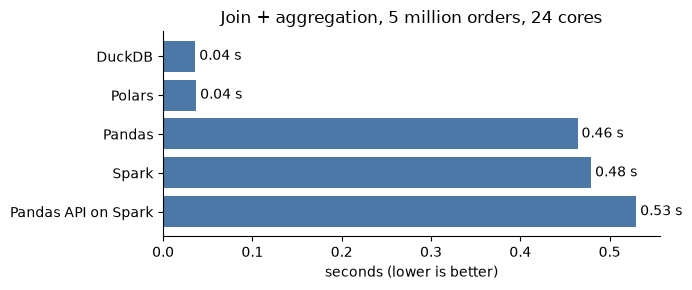

In [6]:
def bar_chart(times, title):
    names = sorted(times, key=times.get)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.barh(names, [times[n] for n in names], color="#4c78a8")
    for i, n in enumerate(names):
        ax.text(times[n], i, f" {times[n]:.2f} s", va="center")
    ax.invert_yaxis()
    ax.set_xlabel("seconds (lower is better)")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()

bar_chart(times, f"Join + aggregation, {N/1e6:.0f} million orders, {os.cpu_count()} cores")

**How to read the result** (the numbers vary by machine, but the order tends to repeat):

- **Polars and DuckDB** are usually the fastest, often by a good margin.
- **Pandas** sits in the middle: it reads fast, but does the joins on a single core and materializes each intermediate step.
- **Spark** pays the fixed cost of planning, tasks and transfer to Python.
- The **Pandas API on Spark** adds to Spark's cost the translation of Pandas semantics (index, order). It was not built to be fast on one machine, but to **scale existing Pandas code**.

### 4.1 Memory

Time is only half the story: Pandas usually breaks from **lack of memory** well before it gets too slow.

To measure this fairly, we run each tool in a **separate Python process** and read the process's peak memory (`VmHWM`, the highest RSS it reached). Spark is left out: the JVM reserves the configured memory right at startup (`spark.driver.memory`), so its peak does not say how much the query needed.

In [7]:
MEMORY_SCRIPTS = {
    "Pandas": f"""
import pandas as pd
o = pd.read_parquet('{ORDERS}', columns=['customer_id','product_id','quantity','price','order_date'])
c = pd.read_parquet('{CUSTOMERS}'); p = pd.read_parquet('{PRODUCTS}', columns=['product_id','category'])
o = o[o['order_date'] >= '{CUTOFF}']; o = o.assign(revenue=o['price'] * o['quantity'])
o.merge(c, on='customer_id').merge(p, on='product_id').groupby(['segment','category'])['revenue'].sum()
""",
    "Polars": f"""
import polars as pl
(pl.scan_parquet('{ORDERS}').filter(pl.col('order_date') >= pl.date(2024, 7, 1))
   .with_columns(revenue=pl.col('price') * pl.col('quantity'))
   .join(pl.scan_parquet('{CUSTOMERS}'), on='customer_id').join(pl.scan_parquet('{PRODUCTS}'), on='product_id')
   .group_by('segment', 'category').agg(pl.col('revenue').sum()).collect())
""",
    "DuckDB": f"""
import duckdb
duckdb.sql(\"\"\"SELECT segment, category, SUM(price * quantity) FROM '{ORDERS}'
  JOIN '{CUSTOMERS}' USING (customer_id) JOIN '{PRODUCTS}' USING (product_id)
  WHERE order_date >= DATE '{CUTOFF}' GROUP BY ALL\"\"\").df()
""",
}

def peak_memory_mb(script):
    # VmHWM = the process's peak resident memory (Linux, in KB)
    wrapper = script + "\nprint([l for l in open('/proc/self/status') if l.startswith('VmHWM')][0].split()[1])"
    out = subprocess.run([sys.executable, "-c", wrapper], capture_output=True, text=True, check=True)
    return int(out.stdout.strip().splitlines()[-1]) / 1024

baseline = peak_memory_mb("import pandas, polars, duckdb")
print(f"Empty Python process (imports only): {baseline:,.0f} MB\n")

memory = {name: peak_memory_mb(s) for name, s in MEMORY_SCRIPTS.items()}
for name, mb in memory.items():
    print(f"{name:<8} peak memory: {mb:7,.0f} MB")
print(f"\norders.parquet file on disk: {os.path.getsize(ORDERS) / 1e6:,.0f} MB")

Empty Python process (imports only): 139 MB

Pandas   peak memory:     873 MB
Polars   peak memory:     317 MB
DuckDB   peak memory:     222 MB

orders.parquet file on disk: 63 MB


Pandas loads whole columns and creates copies at each `merge`. Polars and DuckDB read in batches, filter early and keep only what is needed. An old Pandas rule of thumb: **set aside 5 to 10 times the data size in RAM.**

---
## 5. How the result changes with volume

Let's repeat the query for 1, 5 and 20 million rows, comparing the four main tools.

> On free Colab (about 12 GB of RAM), 20 million works. On smaller machines, change it to 10 million.

In [8]:
SIZES = [1_000_000, 5_000_000, 20_000_000]
scaling = {name: [] for name in ["Pandas", "Polars", "DuckDB", "Spark"]}

ORDERS_ORIGINAL = ORDERS
for n in SIZES:
    ORDERS = f"{BASE}/orders_{n // 1_000_000}M.parquet"
    if not os.path.exists(ORDERS):
        generate_orders(n, seed=n).to_parquet(ORDERS, index=False)
    print(f"--- {n:,} rows")
    t, _ = benchmark({k: QUERIES[k] for k in scaling}, repeat=2)
    for k in scaling:
        scaling[k].append(t[k])
ORDERS = ORDERS_ORIGINAL

--- 1,000,000 rows
Pandas                   0.11 s
Polars                   0.02 s
DuckDB                   0.03 s
Spark                    0.33 s
--- 5,000,000 rows
Pandas                   0.46 s
Polars                   0.04 s
DuckDB                   0.04 s
Spark                    0.34 s
--- 20,000,000 rows
Pandas                   2.14 s
Polars                   0.11 s
DuckDB                   0.08 s
Spark                    0.49 s


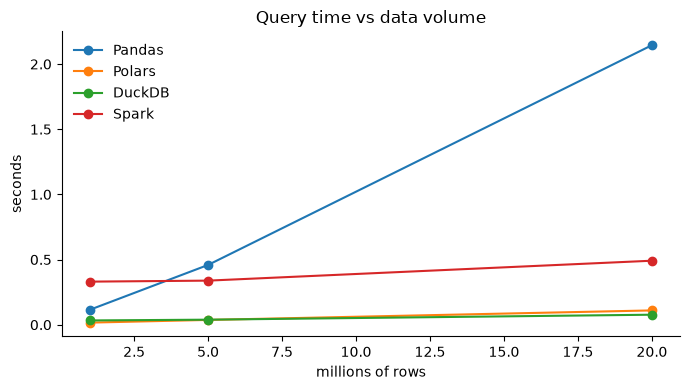

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, ts in scaling.items():
    ax.plot([s / 1e6 for s in SIZES], ts, marker="o", label=name)
ax.set_xlabel("millions of rows"); ax.set_ylabel("seconds")
ax.set_title("Query time vs data volume")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

What to observe:
- Spark's fixed cost weighs more at small volumes; as the volume grows, the relative difference shrinks.
- Pandas grows faster than the others, and at some point no longer fits in memory.
- Polars and DuckDB grow slowly: they use all cores and do not materialize intermediate steps.

**The curve this notebook cannot show** is Spark's on a cluster: with 10 machines, the same code processes 10 times more data in the same time. None of the other tools do that.

---
## 6. Pandas API on Spark in detail

`pyspark.pandas` (formerly the Koalas project) implements much of the Pandas API on top of Spark. The use case is **migration**: you have working Pandas code, the data has grown and no longer fits on one machine.

```python
import pandas as pd              import pyspark.pandas as ps
df = pd.read_parquet(path)  ->   df = ps.read_parquet(path)
df.groupby("x")["y"].mean()      df.groupby("x")["y"].mean()      # same code
```

### Differences that matter

| Topic | Pandas | Pandas API on Spark |
|------|--------|---------------------|
| Index | Always exists, ordered | Has to be **generated**; its type greatly affects performance |
| Row order | Guaranteed | Not guaranteed after distributed operations |
| Execution | Immediate | Lazy (becomes a Spark plan) |
| Row-by-row `df.apply(func)` | Slow | Very slow (Python UDF, Lab 5) |
| `iterrows`, `.values`, `.to_numpy()` | Normal | Bring **everything** to the driver |
| Spark 4 ANSI mode | — | Must be turned off |

### Default index types (`compute.default_index_type`)

| Type | How it is generated | Cost |
|------|-----------|-------|
| `sequence` (default) | 0, 1, 2... in order, **in a single partition** | Bottleneck: all data passes through one task |
| `distributed-sequence` | 0, 1, 2... computed per partition | Medium (one extra job) |
| `distributed` | Increasing but **non-consecutive** IDs | Low; use it when the index does not matter |

In [10]:
psdf = ps.read_parquet(ORDERS, columns=["order_id", "region", "price", "quantity"])
print(type(psdf))
psdf.head(3)

<class 'pyspark.pandas.frame.DataFrame'>


,order_id,region,price,quantity
8589934592,0,Midwest,314.21,5
8589934593,1,Midwest,111.32,3
8589934594,2,Midwest,66.17,4


In [11]:
# Underneath, everything is a Spark plan
summary = psdf.groupby("region")["price"].mean().sort_values(ascending=False)
summary.to_frame().spark.explain()
summary

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [__index_level_0__#648, price#650]
   +- Sort [price#650 DESC NULLS LAST, __natural_order__#656L ASC NULLS FIRST], true, 0
      +- Exchange rangepartitioning(price#650 DESC NULLS LAST, __natural_order__#656L ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=2999]
         +- Project [__index_level_0__#648, price#650, __natural_order__#656L, price#650]
            +- HashAggregate(keys=[__index_level_0__#648], functions=[avg(nanvl(price#640, null))])
               +- Exchange hashpartitioning(__index_level_0__#648, 8), ENSURE_REQUIREMENTS, [plan_id=2995]
                  +- HashAggregate(keys=[__index_level_0__#648], functions=[partial_avg(nanvl(price#640, null))])
                     +- Project [region#641 AS __index_level_0__#648, price#640]
                        +- Filter atleastnnonnulls(1, region#641)
                           +- FileScan parquet [price#640,region#641] Batched: true, DataFilters: [atleastnno

region
South        255.104166
Northeast    255.069831
Midwest      255.023790
North        254.920727
Southeast    254.740372
Name: price, dtype: float64

In [12]:
# Moving between the two worlds
sdf  = psdf.to_spark()            # pandas-on-Spark -> Spark DataFrame (no cost)
back = sdf.pandas_api()           # Spark DataFrame -> pandas-on-Spark (generates an index)
small = psdf.head(1000).to_pandas()   # -> real pandas: only for SMALL results
print(type(sdf).__name__, "|", type(back).__name__, "|", type(small).__name__)

DataFrame | DataFrame | DataFrame


In [13]:
# The cost of the index: the same groupby with each default index type
for idx in ["sequence", "distributed-sequence", "distributed"]:
    ps.set_option("compute.default_index_type", idx)
    t0 = time.perf_counter()
    ps.read_parquet(ORDERS, columns=["region", "price"]).groupby("region")["price"].sum().to_pandas()
    print(f"{idx:<22} {time.perf_counter() - t0:5.2f} s")
ps.set_option("compute.default_index_type", "distributed")

sequence                0.31 s
distributed-sequence    0.17 s
distributed             0.18 s


### Why we turned ANSI mode off

In Spark 4, ANSI mode (Lab 7) is on by default. The Pandas API on Spark mimics Pandas behaviors that conflict with it (for example, division by zero returning `inf`/`NaN` instead of an error), so it refuses to start with ANSI on. That is why we created the session with `spark.sql.ansi.enabled=false`.

---
## 7. Polars in detail

Polars has two modes:
- **Eager** (`pl.read_parquet`, `pl.DataFrame`): runs each step immediately, like Pandas.
- **Lazy** (`pl.scan_parquet`, `df.lazy()`): builds a plan and only runs on `.collect()`, like Spark.

The lazy plan goes through an optimizer with the same ideas as Catalyst.

In [14]:
lazy = (
    pl.scan_parquet(ORDERS)
    .with_columns(revenue=pl.col("price") * pl.col("quantity"))
    .filter(pl.col("region") == "South")
    .group_by("product_id")
    .agg(pl.col("revenue").sum())
    .sort("revenue", descending=True)
    .head(5)
)
print(lazy.explain())

SORT BY [slice: (0, 5, dynamic_pred: a5b3bbf4-8e7a-4fe9-8636-0a007be10649), descending: [true]] [col("revenue")]
  FILTER col("revenue").dynamic_predicate()
  FROM
    AGGREGATE[maintain_order: false]
      [col("revenue").sum()] BY [col("product_id")]
      FROM
      simple π 2/2 ["product_id", "revenue"]
         WITH_COLUMNS:
         [(col("price") * col("quantity").cast(Float64)).alias("revenue")] 
          simple π 3/3 ["product_id", "quantity", ... 1 other column]
            Parquet SCAN [/tmp/lab12/orders.parquet]
            PROJECT 4/7 COLUMNS
            SELECTION: col("region") == "South"
            ESTIMATED ROWS: 5000000


In the optimized plan, the Parquet read already receives the filter (`SELECTION`) and only the columns used (`PROJECT 4/7 COLUMNS`): predicate and column pruning, as in Spark's `FileScan`.

### Expressions and window functions

Equivalences with PySpark:

| PySpark | Polars |
|---------|--------|
| `F.col("x")` | `pl.col("x")` |
| `df.withColumn("y", expr)` | `df.with_columns(y=expr)` |
| `df.groupBy("k").agg(...)` | `df.group_by("k").agg(...)` |
| `F.when(c, a).otherwise(b)` | `pl.when(c).then(a).otherwise(b)` |
| `F.sum("x").over(Window.partitionBy("k"))` | `pl.col("x").sum().over("k")` |
| `F.rank().over(...)` | `pl.col("x").rank(...).over("k")` |

In [15]:
top3 = (
    pl.scan_parquet(ORDERS)
    .join(pl.scan_parquet(PRODUCTS), on="product_id")
    .group_by("region", "product_name")
    .agg(revenue=(pl.col("price") * pl.col("quantity")).sum())
    .with_columns(rank=pl.col("revenue").rank("dense", descending=True).over("region"))
    .filter(pl.col("rank") <= 3)
    .sort("region", "rank")
    .collect()
)
top3

region,product_name,revenue,rank
str,str,f64,u32
"""Midwest""","""Product 395""",878056.63,1
"""Midwest""","""Product 922""",858427.85,2
"""Midwest""","""Product 967""",851615.18,3
"""North""","""Product 644""",881617.56,1
"""North""","""Product 291""",874203.92,2
…,…,…,…
"""South""","""Product 639""",855680.56,2
"""South""","""Product 202""",853505.02,3
"""Southeast""","""Product 517""",860639.56,1


In [16]:
# Streaming engine: processes in batches, allowing data larger than memory.
# The code is the same; only the collect argument changes.
for engine in ["in-memory", "streaming"]:
    t0 = time.perf_counter()
    res = lazy.collect(engine=engine)
    print(f"engine {engine:<10} {time.perf_counter() - t0:.2f} s")
res

engine in-memory  0.01 s
engine streaming  0.01 s


product_id,revenue
i32,f64
156,863121.24
639,855680.56
202,853505.02
85,845877.06
735,844340.72


---
## 8. DuckDB in detail

DuckDB is an **embedded** analytical database: there is no server, it runs inside the Python process, like SQLite, but optimized for analytical queries.

Three features make it very practical:
1. **Direct SQL on files**: Parquet, CSV, JSON, including wildcards (`'folder/*.parquet'`) and on S3.
2. **Direct SQL on Pandas, Polars or Arrow DataFrames** held in Python variables, with no copy.
3. **Out-of-core**: when memory runs out, it uses disk instead of breaking.

In [17]:
# 1) SQL on a file, with EXPLAIN
print(duckdb.sql(f"EXPLAIN SELECT region, AVG(price) FROM '{ORDERS}' WHERE quantity > 3 GROUP BY region").fetchall()[0][1])

╭─ Hash Group By ────────╮
│ Groups: #0             │
│ Aggregates: avg(#1)    │
│ ~632,120 rows          │
╰────────────┬───────────╯
╭─ Projection ───────────╮
│ Projections: region,   │
│              price     │
│ ~1,000,000 rows        │
╰────────────┬───────────╯
╭─ Parquet Scan ─────────╮
│ Function: PARQUET_SCAN │
│ Projections: region,   │
│              price     │
│ Filters: quantity > 3  │
│ ~1,000,000 rows        │
╰────────────────────────╯



In [18]:
# 2) SQL on an in-memory Pandas DataFrame (the variable name becomes a table)
regions_pd = pd.DataFrame({"region": REGIONS, "manager": ["Ana", "Bruno", "Carla", "Diego", "Elisa"]})

duckdb.sql(f"""
    SELECT r.manager, o.region, ROUND(SUM(o.price * o.quantity), 2) AS revenue
    FROM '{ORDERS}' o
    JOIN regions_pd r USING (region)
    GROUP BY ALL
    ORDER BY revenue DESC
""").pl()      # .df() -> Pandas | .pl() -> Polars | .arrow() -> Arrow | .fetchall() -> tuples

manager,region,revenue
str,str,f64
"""Carla""","""Midwest""",7.6603e8
"""Ana""","""North""",7.6481e8
"""Elisa""","""South""",7.6465e8
"""Bruno""","""Northeast""",7.6395e8
"""Diego""","""Southeast""",7.6332e8


In [19]:
# 3) Out-of-core: we limit memory to 300 MB and run an aggregation with 5 million groups
con = duckdb.connect()
con.sql("SET memory_limit = '300MB'")
con.sql(f"SET temp_directory = '{BASE}/duckdb_tmp'")

t0 = time.perf_counter()
n_groups = con.execute(f"""
    SELECT COUNT(*) FROM (
        SELECT order_id, SUM(price) FROM '{ORDERS}' GROUP BY order_id
    )
""").fetchone()[0]
print(f"{n_groups:,} groups with a 300 MB limit in {time.perf_counter() - t0:.2f} s")
con.close()

5,000,000 groups with a 300 MB limit in 0.07 s


In [20]:
# DuckDB can write too: a partitioned Parquet, like Spark's partitionBy
duckdb.sql(f"""
    COPY (SELECT *, month(order_date) AS month FROM '{ORDERS}' WHERE region = 'South')
    TO '{BASE}/south_by_month' (FORMAT parquet, PARTITION_BY (month), OVERWRITE_OR_IGNORE)
""")
print(sorted(os.listdir(f"{BASE}/south_by_month"))[:4], "...")

['month=1', 'month=10', 'month=11', 'month=12'] ...


---
## 9. Apache Arrow: the common language

All these tools speak **Apache Arrow**, a standard in-memory columnar format. That is why exchanging data between them is fast, often with no copy.

```
                        ┌───────────────┐
        Pandas ◀──────▶ │               │ ◀──────▶ Polars
                        │ Apache Arrow  │
        DuckDB ◀──────▶ │ (columnar, in │ ◀──────▶ Spark (toArrow / createDataFrame)
                        │  memory)      │
       Parquet ◀──────▶ │               │ ◀──────▶ ML (PyTorch, scikit-learn via NumPy)
                        └───────────────┘
```

This allows **combining tools**: Spark for heavy ETL on the cluster, DuckDB to explore the result, Polars to prepare features and Pandas for the final chart.

In [21]:
arrow_tbl = duckdb.sql(f"SELECT * FROM '{ORDERS}' LIMIT 1000000").arrow()
if not isinstance(arrow_tbl, pa.Table):          # recent DuckDB versions return a RecordBatchReader
    arrow_tbl = arrow_tbl.read_all()

pdf_1m = arrow_tbl.to_pandas()

conversions = {
    "Arrow  -> Polars": lambda: pl.from_arrow(arrow_tbl),
    "Arrow  -> Pandas": lambda: arrow_tbl.to_pandas(),
    "Pandas -> DuckDB": lambda: duckdb.sql("SELECT COUNT(*) FROM pdf_1m").fetchall(),
    "Polars -> Pandas": lambda: pl.from_arrow(arrow_tbl).to_pandas(),
    "Pandas -> Spark":  lambda: spark.createDataFrame(pdf_1m).count(),
    "Spark  -> Pandas": lambda: spark.read.parquet(ORDERS).limit(1_000_000).toPandas(),
}
print("1 million rows:")
for name, fn in conversions.items():
    t0 = time.perf_counter(); fn()
    print(f"  {name:<18} {time.perf_counter() - t0:6.3f} s")

1 million rows:
  Arrow  -> Polars    0.003 s
  Arrow  -> Pandas    0.017 s
  Pandas -> DuckDB    0.002 s
  Polars -> Pandas    0.030 s
  Pandas -> Spark     1.704 s
  Spark  -> Pandas    0.890 s


Conversions between Pandas, Polars, DuckDB and Arrow take milliseconds. Getting in and out of Spark costs more, because the data crosses from Python to the JVM.

### Arrow in Spark: a setting that makes a big difference

In PySpark 4.0, using Arrow in `toPandas()` and `createDataFrame(pandas_df)` is still **off by default** (`spark.sql.execution.arrow.pyspark.enabled=false`). We turned it on in the setup. See the difference:

In [22]:
sample = pdf_1m.head(300_000)
for enabled in ["false", "true"]:
    spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", enabled)
    t0 = time.perf_counter(); spark.createDataFrame(sample).count(); t_in = time.perf_counter() - t0
    t0 = time.perf_counter(); spark.read.parquet(ORDERS).limit(300_000).toPandas(); t_out = time.perf_counter() - t0
    print(f"Arrow {enabled:<5} | Pandas -> Spark {t_in:6.2f} s | Spark -> Pandas {t_out:6.2f} s")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")

Arrow false | Pandas -> Spark   5.09 s | Spark -> Pandas   1.35 s
Arrow true  | Pandas -> Spark   0.52 s | Spark -> Pandas   0.31 s


Without Arrow, each row is converted into a Python object and serialized individually. With Arrow, whole columns are transferred in batches. **Always turn this setting on when exchanging data between Pandas and Spark.**

---
## 10. How to decide

```
                      Does the data fit comfortably
                      on ONE machine (including spilling to disk)?
                              │
               ┌───── NO ─────┴───── YES ────┐
               ▼                             ▼
            SPARK                   What exists already / what does the team prefer?
     (cluster, streaming,                    │
      Delta, distributed MLlib)   ┌──────────┼────────────┬─────────────────┐
               │                  ▼          ▼            ▼                 ▼
     Legacy Pandas code      SQL team      New Python    Quick             Small legacy
     that needs to scale?        │         pipeline      exploration, <1GB Pandas code
               │                 ▼             ▼            ▼                 ▼
     PANDAS API ON SPARK      DUCKDB        POLARS       PANDAS            PANDAS
```

| Situation | Tool |
|----------|------------|
| Tens of GB to TB, or data that will grow a lot | Spark |
| Streaming, Delta Lake, MLlib, a cluster already exists | Spark |
| Pandas code that no longer fits in memory | Pandas API on Spark (or rewrite in Polars) |
| Up to tens of GB on one machine, a team that thinks in SQL | DuckDB |
| Up to tens of GB on one machine, a Python pipeline | Polars |
| Quick exploration, a few MB, integration with everything | Pandas |

Two warnings so as not to overdo it in the other direction:
- "Fits on one machine" depends on the machine. A cloud VM with 256 GB of RAM processes a lot with DuckDB or Polars, and sometimes costs less than a cluster.
- Spark is not only about speed: it brings **fault tolerance, horizontal scaling and an ecosystem** (Delta, streaming, catalogs, scheduling) that the other tools do not replace.

---
## 11. Exercises

In [23]:
# ── Exercise 1 ──────────────────────────────────────────────────────────────
# Average ticket (revenue / orders) per month, only for the "Southeast" region.
# Write it in Polars (lazy) and in DuckDB, check that the results match and compare the times.

# Your solution:
t0 = time.perf_counter()
sol_pl = (
    pl.scan_parquet(ORDERS)
    .filter(pl.col("region") == "Southeast")
    .group_by(month=pl.col("order_date").dt.month())
    .agg(avg_ticket=(pl.col("price") * pl.col("quantity")).mean())
    .sort("month")
    .collect()
)
t_pl = time.perf_counter() - t0

t0 = time.perf_counter()
sol_db = duckdb.sql(f"""
    SELECT month(order_date) AS month, AVG(price * quantity) AS avg_ticket
    FROM '{ORDERS}' WHERE region = 'Southeast'
    GROUP BY month ORDER BY month
""").pl()
t_db = time.perf_counter() - t0

print(f"Polars {t_pl:.2f} s | DuckDB {t_db:.2f} s")
print("Equal:", np.allclose(sol_pl["avg_ticket"].to_numpy(), sol_db["avg_ticket"].to_numpy()))
sol_pl.head(3)

Polars 0.02 s | DuckDB 0.02 s
Equal: True


month,avg_ticket
i8,f64
1,762.094426
2,762.503229
3,763.034853


In [24]:
# ── Exercise 2 ──────────────────────────────────────────────────────────────
# The Pandas code below computes, for each customer, total revenue and number of orders,
# and then keeps the 100 customers with the highest revenue. Migrate it to the Pandas API on Spark
# changing as little as possible and check that the result is the same.

def top_customers_pandas():
    o = pd.read_parquet(ORDERS, columns=["customer_id", "price", "quantity"])
    o["revenue"] = o["price"] * o["quantity"]
    agg = o.groupby("customer_id").agg(revenue=("revenue", "sum"), orders=("revenue", "count"))
    return agg.sort_values("revenue", ascending=False).head(100)

# Your solution:
def top_customers_ps():
    o = ps.read_parquet(ORDERS, columns=["customer_id", "price", "quantity"])   # pd -> ps
    o["revenue"] = o["price"] * o["quantity"]
    agg = o.groupby("customer_id").agg(revenue=("revenue", "sum"), orders=("revenue", "count"))
    return agg.sort_values("revenue", ascending=False).head(100).to_pandas()    # + to_pandas()

a, b = top_customers_pandas(), top_customers_ps()
pd.testing.assert_frame_equal(a.sort_index(), b.sort_index(), check_dtype=False)
print("Same results. Changes: pd -> ps and .to_pandas() on the final (small) result.")

Same results. Changes: pd -> ps and .to_pandas() on the final (small) result.


In [25]:
# ── Exercise 3 ──────────────────────────────────────────────────────────────
# Use DuckDB to query an in-memory POLARS DataFrame:
# create in Polars a table of monthly targets per region (target = 65,000,000 for all),
# and with SQL compare each month/region's actual revenue with the target (difference and % reached).

# Your solution:
targets = pl.DataFrame({"region": REGIONS.tolist()}).join(
    pl.DataFrame({"month": list(range(1, 13))}), how="cross"
).with_columns(target=pl.lit(65_000_000))

duckdb.sql(f"""
    WITH real AS (
        SELECT region, month(order_date) AS month, SUM(price * quantity) AS revenue
        FROM '{ORDERS}' GROUP BY ALL
    )
    SELECT t.region, t.month,
           ROUND(r.revenue)                        AS revenue,
           ROUND(r.revenue - t.target)             AS diff,
           ROUND(100 * r.revenue / t.target, 1)    AS pct_target
    FROM targets t JOIN real r USING (region, month)
    ORDER BY pct_target DESC
    LIMIT 5
""").pl()

region,month,revenue,diff,pct_target
str,i64,f64,f64,f64
"""Midwest""",7,6.5363512e7,363512.0,100.6
"""South""",10,6.5402052e7,402052.0,100.6
"""Northeast""",10,6.532188e7,321880.0,100.5
"""South""",3,6.5260618e7,260618.0,100.4
"""North""",10,6.5268939e7,268939.0,100.4


**Exercise 4 (discussion).** Which tool would you choose in each scenario? Justify your answer.

1. An analyst receives a 300 MB CSV by email and needs three charts by the end of the day.
2. A daily pipeline reads 2 TB of logs from S3, joins them with Delta tables and writes the Silver layer.
3. A BI team wants to query 15 GB Parquet files with SQL, in their own notebook, without a cluster.
4. A forecasting model in Pandas worked with 1 year of history; now it must run with 10 years (80 GB).
5. An API must respond in under 100 ms with aggregations over a 500 MB file.

**Solution:**

1. **Pandas** (or Polars). 300 MB fits easily; the cost of setting up anything else does not pay off.
2. **Spark.** 2 TB, a distributed source and Delta tables: exactly its use case.
3. **DuckDB.** Direct SQL on the files, no server, spilling to disk if memory runs short.
4. **Pandas API on Spark** to migrate quickly while reusing the code; in the medium term, consider rewriting in Polars (if one large machine is enough) or in PySpark.
5. **DuckDB or Polars** loaded once in the service's memory. Spark is not suited to per-query millisecond latency.

---
## Summary

| | Pandas | Polars | DuckDB | Pandas API on Spark | Spark |
|-|--------|--------|--------|---------------------|-------|
| Best for | Exploration, small data | Python pipelines on 1 machine | Analytical SQL on 1 machine | Scaling Pandas code | Distributed data, ecosystem |
| Read Parquet | `pd.read_parquet` | `pl.scan_parquet` | `FROM 'file.parquet'` | `ps.read_parquet` | `spark.read.parquet` |
| Aggregate | `groupby().agg()` | `group_by().agg()` | `GROUP BY` | `groupby().agg()` | `groupBy().agg()` |
| Lazy | No | `scan_*` / `.lazy()` | Always | Yes | Yes |
| See the plan | — | `.explain()` | `EXPLAIN` | `.spark.explain()` | `.explain()` |
| To Pandas | — | `.to_pandas()` | `.df()` | `.to_pandas()` | `.toPandas()` |

In [26]:
spark.stop()